# 01 · Explore Data: Hanoi PM2.5 (2016–2020)

**Project:** Seeing Hanoi's Air: A Visual Analytics Study of PM2.5 Patterns and a SHAP-Explained Forecasting Model

**This notebook answers the PM2.5 part of RQ1:**
> What seasonal and day-of-week patterns does daily PM2.5 in Hanoi show, and when do high-pollution days cluster?

The weather part of RQ1 (wind, rain, temperature) follows in `02_weather.ipynb`, after the Open-Meteo data is merged.

**Workflow** (Week 11 EDA procedure): data inventory → profiling → distributions → temporal patterns → synthesis.
Each figure is read with the same four steps: **Describe → Notice → Limit → Check next**.

**Data:** `hanoi-us embassy vietnam-air-quality.csv` from the Kaggle dataset *AQI Jakarta, Hanoi, Bangkok, Kuala Lumpur* (yasirabd). Download instructions are in the repository README.

## 0. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import ListedColormap, BoundaryNorm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROC = ROOT / "data" / "processed"
FIG = ROOT / "figures"
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# Okabe–Ito (colour-blind safe) for categories
OI = {"orange": "#E69F00", "sky": "#56B4E9", "green": "#009E73", "yellow": "#F0E442",
      "blue": "#0072B2", "vermillion": "#D55E00", "purple": "#CC79A7", "black": "#000000"}
GREY = "#BDBDBD"

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 8, "axes.labelsize": 7,
    "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6.5,
    "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight",
})
MM = 1 / 25.4
W2 = 183 * MM   # double-column width
W1 = 89 * MM    # single-column width

def save(fig, name):
    fig.savefig(FIG / f"{name}.png")
    fig.savefig(FIG / f"{name}.svg")
    fig.savefig(FIG / f"{name}.pdf")

## 1. Data inventory

In [2]:
src = sorted(RAW.glob("*hanoi*air*quality*.csv"))
assert src, f"Put the Kaggle CSV in {RAW} (see README)."
raw = pd.read_csv(src[0], skipinitialspace=True)
raw.columns = raw.columns.str.strip()
print("File:", src[0].name)
print("Shape:", raw.shape)
display(raw.head(3))
print(raw.dtypes)

File: hanoi-us embassy vietnam-air-quality.csv
Shape: (2477, 7)


,date,pm25,o3,no2,so2,co,aqi
0,2020/12/1,152.0,4.0,12.0,2.0,NaN,NaN
1,2020/12/2,163.0,5.0,8.0,1.0,NaN,NaN
2,2020/12/3,137.0,5.0,8.0,1.0,NaN,NaN


date        str
pm25    float64
o3      float64
no2     float64
so2     float64
co      float64
aqi     float64
dtype: object


Pollutant columns are read as text because empty cells are stored as a single space. They are converted to numbers below. The `date` column uses `YYYY/M/D` without zero padding, and the rows are **not** in date order.

In [3]:
df = raw.copy()
df["date"] = pd.to_datetime(df["date"], format="%Y/%m/%d")
for c in ["pm25", "o3", "no2", "so2", "co", "aqi"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df = df.sort_values("date").set_index("date")
df.head()

,pm25,o3,no2,so2,co,aqi
date,,,,,,
2014-01-01,NaN,NaN,40.0,6.0,28.0,NaN
2014-01-02,NaN,22.0,39.0,8.0,43.0,NaN
2014-01-03,NaN,69.0,25.0,12.0,28.0,NaN
2014-01-04,NaN,24.0,NaN,NaN,NaN,NaN
2014-01-05,NaN,NaN,35.0,5.0,33.0,NaN


## 2. Profiling

| Check | Question |
|---|---|
| 1 Structure | What does one row represent? |
| 2 Meaning | What unit are the values in? |
| 3 Completeness | Which cells are missing, and when? |
| 4 Uniqueness | Is each date recorded once? |
| 5 Validity | Are values inside the documented range? |
| 6 Consistency | Do related columns agree? |
| 7 Distribution | Where do values cluster? |
| 8 Coverage / timing | Which period can the analysis use? |

### Checks 1–2 · Structure and meaning

One row = one calendar day at the US Embassy monitor in Hanoi. The file follows the format of the **World Air Quality Index project (aqicn.org)**, which publishes every pollutant **converted to the US EPA AQI scale, not as raw concentrations** (aqicn Data Platform documentation).

So `pm25 = 152` means a PM2.5 **AQI of 152**, not 152 µg/m³. All analysis below stays in AQI units. The categories used are the US EPA bands:

| AQI | Category | PM2.5 (µg/m³, 24 h, pre-2024 EPA breakpoints) |
|---|---|---|
| 0–50 | Good | 0–12.0 |
| 51–100 | Moderate | 12.1–35.4 |
| 101–150 | Unhealthy for Sensitive Groups | 35.5–55.4 |
| 151–200 | Unhealthy | 55.5–150.4 |
| 201–300 | Very Unhealthy | 150.5–250.4 |

**High-pollution day** in this project = **PM2.5 AQI > 150** (Unhealthy or worse), equivalent to ≥ 55.5 µg/m³.

### Checks 3–4 · Completeness and uniqueness

In [4]:
print("Duplicate dates:", df.index.duplicated().sum())
print("Date range in file:", df.index.min().date(), "→", df.index.max().date())

obs_by_year = df.notna().groupby(df.index.year).sum()
obs_by_year["calendar_days"] = df.index.to_series().groupby(df.index.year).size()
obs_by_year

Duplicate dates: 0
Date range in file: 2014-01-01 → 2020-12-07


,pm25,o3,no2,so2,co,aqi,calendar_days
date,,,,,,,
2014,0,342,343,237,342,0,353
2015,4,326,327,294,334,119,345
2016,353,229,223,202,230,0,362
2017,332,196,200,310,35,0,363
2018,347,0,0,113,0,0,356
2019,234,155,140,40,0,0,356
2020,342,262,314,299,0,0,342


| Step | Evidence and response |
|---|---|
| Describe | 2,477 rows, 2014-01-01 to 2020-12-07, no duplicate dates. PM2.5 is present only from late December 2015. The `aqi` column exists only in 2015 (119 days) and never overlaps with `pm25`. |
| Notice | Gas columns (`o3`, `no2`, `so2`, `co`) are patchy: `co` stops after 2017 and 2018 has no `o3`/`no2`. |
| Limit | Row count is not day count: dates with no measurement at all are simply absent from the file. |
| Check next | Restrict to the PM2.5 period, re-index to a full daily calendar, and measure the gaps. |

### Check 5 · Validity

In [5]:
display(df.describe().T.round(1))
print("o3 values > 200:")
print(df.loc[df["o3"] > 200, "o3"])

,count,mean,std,min,25%,50%,75%,max
pm25,1612.0,107.5,39.4,6.0,78.0,103.0,136.0,235.0
o3,1510.0,21.8,36.6,1.0,6.0,12.0,21.0,500.0
no2,1547.0,14.9,10.4,1.0,7.0,12.0,22.0,74.0
so2,1495.0,11.8,10.3,1.0,3.0,11.0,14.0,61.0
co,941.0,21.2,11.2,1.0,14.0,19.0,25.0,102.0
aqi,119.0,122.0,37.3,29.0,91.0,119.0,153.0,212.0


o3 values > 200:
date
2015-09-06    401.0
2015-09-07    500.0
2015-09-11    241.0
2017-08-23    498.0
Name: o3, dtype: float64


| Step | Evidence and response |
|---|---|
| Describe | PM2.5 AQI ranges 6–235, inside the 0–500 AQI scale. |
| Notice | Ozone has isolated values of 401–500 in September 2015 and 498 on 2017-08-23, far above its other values. |
| Limit | These may be sensor faults or real spikes; the file alone cannot tell. |
| Check next | Gases are **out of scope** for this project (they are incomplete and not in the RQs). Keep PM2.5 only. |

### Check 8 · Coverage: the PM2.5 study period

In [6]:
START, END = "2016-01-01", "2020-12-07"
days = pd.date_range(START, END, freq="D")
pm = df["pm25"].reindex(days).rename("pm25_aqi")
pm.index.name = "date"

print(f"Calendar days: {len(pm)}  observed: {pm.notna().sum()}  missing: {pm.isna().sum()} "
      f"({pm.isna().mean():.1%})")

miss = pm.isna()
run_id = (miss != miss.shift()).cumsum()
gaps = (pm[miss].groupby(run_id[miss])
        .apply(lambda s: pd.Series({"start": s.index.min().date(), "end": s.index.max().date(), "days": len(s)}))
        .unstack().sort_values("days", ascending=False).reset_index(drop=True))
print("\nGap lengths (days) → count:", gaps["days"].value_counts().sort_index().to_dict())
gaps.head(6)

Calendar days: 1803  observed: 1608  missing: 195 (10.8%)

Gap lengths (days) → count: {1: 12, 2: 5, 3: 3, 4: 3, 5: 2, 10: 1, 13: 1, 119: 1}


,start,end,days
0,2019-05-01,2019-08-27,119
1,2017-10-31,2017-11-12,13
2,2017-12-09,2017-12-18,10
3,2016-06-30,2016-07-04,5
4,2017-04-28,2017-05-02,5
5,2017-09-07,2017-09-10,4


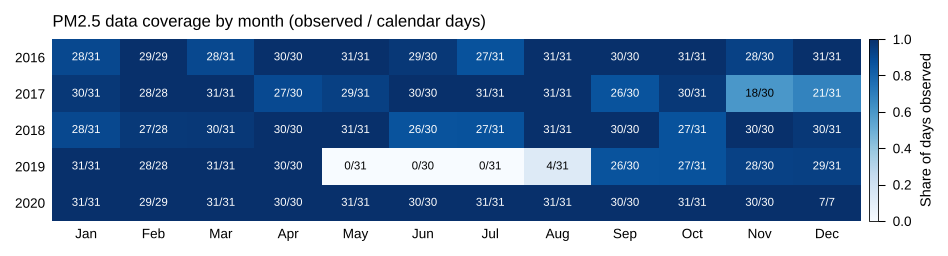

In [7]:
cov = pm.notna().groupby([pm.index.year, pm.index.month]).mean().unstack()
ndays = pm.groupby([pm.index.year, pm.index.month]).size().unstack()
obs = pm.notna().groupby([pm.index.year, pm.index.month]).sum().unstack()

fig, ax = plt.subplots(figsize=(W2, 40 * MM))
im = ax.imshow(cov.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for i in range(cov.shape[0]):
    for j in range(cov.shape[1]):
        if not np.isnan(cov.values[i, j]):
            v = cov.values[i, j]
            ax.text(j, i, f"{int(obs.values[i, j])}/{int(ndays.values[i, j])}", ha="center", va="center",
                    fontsize=5.5, color="white" if v > 0.6 else "black")
ax.set_xticks(range(12), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_yticks(range(len(cov.index)), cov.index)
ax.spines[:].set_visible(False)
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
cb.set_label("Share of days observed")
cb.outline.set_linewidth(0.4)
ax.set_title("PM2.5 data coverage by month (observed / calendar days)", loc="left")
save(fig, "fig01_coverage")
plt.show()

| Step | Evidence and response |
|---|---|
| Describe | 1,803 calendar days from 2016-01-01 to 2020-12-07; 1,608 observed (89.2%), 195 missing. |
| Notice | Most gaps are 1–5 days. One gap is long: **119 days from 2019-05-01 to 2019-08-27**, plus 13 days from 2017-10-31 and 10 days from 2017-12-09. |
| Limit | The 2019 gap falls in May–August, the cleanest months. A 2019 annual average computed from the remaining days will be **biased upward**. |
| Check next | Compare years month by month rather than by annual averages. For RQ2, lag features must not bridge gaps silently: rows whose lag days are missing are dropped, and no gap is interpolated across more than a few days. |

## 3. Distribution

In [8]:
BINS = [0, 50, 100, 150, 200, 300]
LABELS = ["Good", "Moderate", "Unhealthy for\nsensitive groups", "Unhealthy", "Very unhealthy"]
CAT_COL = ["#FDE0C5", "#FAC090", "#F48A5A", "#C8453C", "#7A1F3D"]   # sequential, ordinal

x = pm.dropna()
cat = pd.cut(x, BINS, labels=LABELS)
share = cat.value_counts(sort=False)
tab = pd.DataFrame({"days": share, "share_%": (share / share.sum() * 100).round(1)})
print(f"n = {len(x)} days · median {x.median():.0f} · IQR {x.quantile(.25):.0f}–{x.quantile(.75):.0f} · "
      f"mean {x.mean():.1f} · max {x.max():.0f}")
print(f"High-pollution days (AQI > 150): {(x > 150).sum()} ({(x > 150).mean():.1%})")
tab

n = 1608 days · median 103 · IQR 78–136 · mean 107.5 · max 235
High-pollution days (AQI > 150): 266 (16.5%)


,days,share_%
pm25_aqi,,
Good,80,5.0
Moderate,693,43.1
Unhealthy for\nsensitive groups,569,35.4
Unhealthy,249,15.5
Very unhealthy,17,1.1


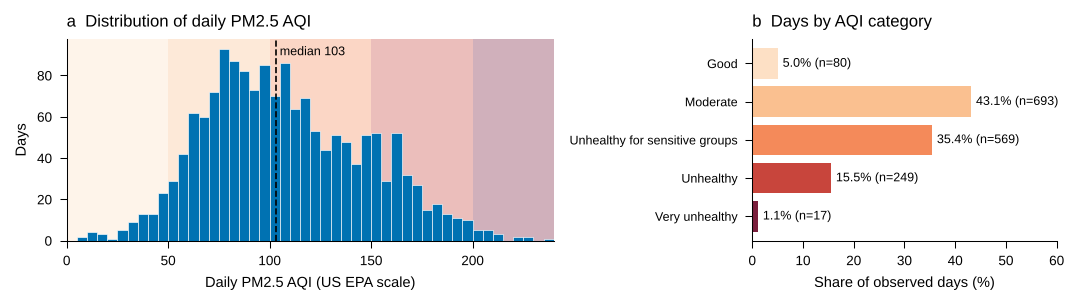

In [9]:
fig, (a, b) = plt.subplots(1, 2, figsize=(W2, 52 * MM), gridspec_kw={"width_ratios": [1.6, 1]})

for lo, hi, c in zip(BINS[:-1], BINS[1:], CAT_COL):
    a.axvspan(lo, hi, color=c, alpha=0.35, lw=0)
a.hist(x, bins=np.arange(0, 245, 5), color=OI["blue"], edgecolor="white", linewidth=0.3)
a.axvline(x.median(), color=OI["black"], lw=0.8, ls="--")
a.text(x.median() + 2, a.get_ylim()[1] * 0.92, f"median {x.median():.0f}", fontsize=6)
a.set_xlim(0, 240)
a.set_xlabel("Daily PM2.5 AQI (US EPA scale)")
a.set_ylabel("Days")
a.set_title("a  Distribution of daily PM2.5 AQI", loc="left")

y = np.arange(len(tab))[::-1]
b.barh(y, tab["share_%"], color=CAT_COL, edgecolor="none")
for yi, (d, s) in zip(y, zip(tab["days"], tab["share_%"])):
    b.text(s + 1, yi, f"{s:.1f}% (n={d})", va="center", fontsize=6)
b.set_yticks(y, [l.replace("\n", " ") for l in LABELS], fontsize=6)
b.set_xlim(0, 60)
b.set_xlabel("Share of observed days (%)")
b.set_title("b  Days by AQI category", loc="left")
fig.tight_layout()
save(fig, "fig02_distribution")
plt.show()

| Step | Evidence and response |
|---|---|
| Describe | Median AQI 103 (IQR 78–136), n = 1,608 days. 43.1% of days are Moderate and 35.4% Unhealthy for Sensitive Groups. **266 days (16.5%) exceed AQI 150** (15.5% Unhealthy, 1.1% Very Unhealthy); no day reaches Hazardous. |
| Notice | Only 5.0% of days are Good. The distribution is broad, with a long upper shoulder rather than a single tail. |
| Limit | Pooling all days hides *when* the high values occur. AQI is a piecewise-linear transform of concentration, so equal AQI steps are not equal µg/m³ steps. |
| Check next | Split by month and year to see whether the upper shoulder is seasonal. |

## 4. Temporal patterns

### 4.1 The full series

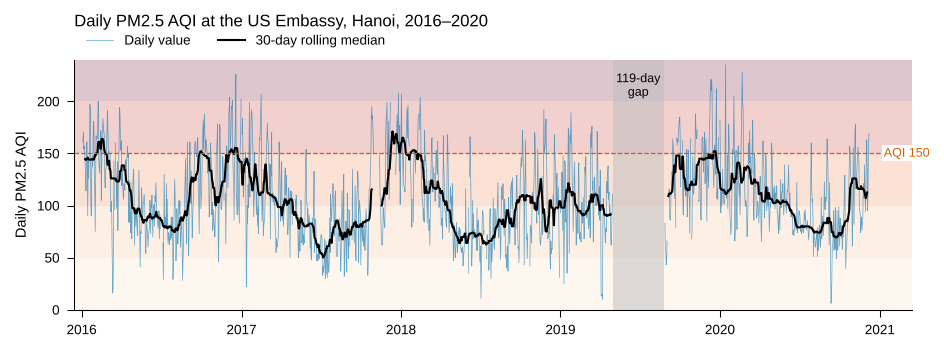

In [10]:
roll = pm.rolling(30, center=True, min_periods=20).median()

fig, ax = plt.subplots(figsize=(W2, 55 * MM))
for lo, hi, c in zip(BINS[:-1], BINS[1:], CAT_COL):
    ax.axhspan(lo, hi, color=c, alpha=0.25, lw=0)
ax.plot(pm.index, pm.values, color=OI["blue"], lw=0.35, alpha=0.6, label="Daily value")
ax.plot(roll.index, roll.values, color=OI["black"], lw=1.0, label="30-day rolling median")
ax.axvspan(pd.Timestamp("2019-05-01"), pd.Timestamp("2019-08-27"), color=GREY, alpha=0.5, lw=0)
ax.text(pd.Timestamp("2019-06-28"), 228, "119-day\ngap", ha="center", va="top", fontsize=6)
ax.axhline(150, color=OI["vermillion"], lw=0.6, ls="--")
ax.text(pd.Timestamp("2021-01-10"), 150, "AQI 150", color=OI["vermillion"], fontsize=6, va="center",
        bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.set_ylim(0, 240)
ax.set_ylabel("Daily PM2.5 AQI")
ax.set_xlim(pd.Timestamp("2015-12-15"), pd.Timestamp("2021-03-15"))
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False, ncol=2)
ax.set_title("Daily PM2.5 AQI at the US Embassy, Hanoi, 2016–2020", loc="left", pad=16)
save(fig, "fig03_timeseries")
plt.show()

| Step | Evidence and response |
|---|---|
| Describe | The 30-day median rises every winter and falls every summer, in all five years. |
| Notice | The seasonal swing (roughly AQI 75 in summer to 135 in winter) is larger than any difference between years. Daily values jump far above and below the rolling median within days. |
| Limit | A line chart over five years compresses individual days; it cannot show which specific dates were extreme. |
| Check next | A calendar heatmap to locate the episodes, and a month-level summary to quantify the season. |

### 4.2 Calendar heatmap

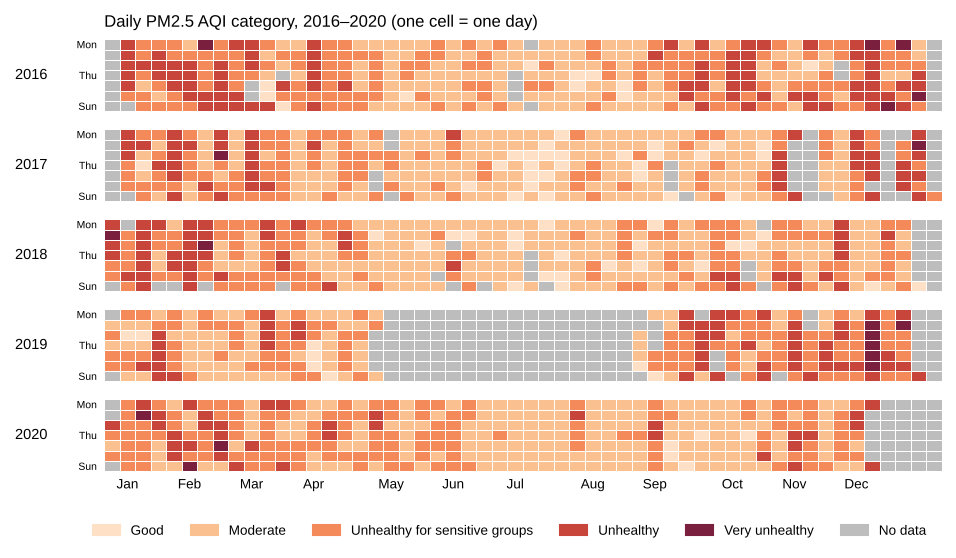

In [11]:
cmap = ListedColormap(CAT_COL)
cmap.set_bad(GREY)
norm = BoundaryNorm(BINS, cmap.N)

years = sorted(set(pm.index.year))
fig, axes = plt.subplots(len(years), 1, figsize=(W2, 95 * MM), sharex=True)
for ax, yr in zip(axes, years):
    s = pm[str(yr)]
    first = pd.Timestamp(f"{yr}-01-01")
    grid = np.full((7, 54), np.nan)
    for d, v in s.items():
        grid[d.dayofweek, int(d.strftime("%U"))] = v   # %U = week of year (Sunday start)
    m = np.ma.masked_invalid(grid)
    ax.pcolormesh(m, cmap=cmap, norm=norm, edgecolors="white", linewidth=0.3)
    # grey only for days that exist in the calendar but were not observed
    exists = np.zeros((7, 54), bool)
    for d in pd.date_range(first, min(pd.Timestamp(f"{yr}-12-31"), pm.index.max())):
        exists[d.dayofweek, int(d.strftime("%U"))] = True
    miss_grid = np.ma.masked_where(~(exists & np.isnan(grid)), np.ones((7, 54)))
    ax.pcolormesh(miss_grid, cmap=ListedColormap([GREY]), edgecolors="white", linewidth=0.3)
    ax.set_ylim(7, 0)
    ax.set_yticks([0.5, 3.5, 6.5], ["Mon", "Thu", "Sun"], fontsize=5)
    ax.set_ylabel(yr, rotation=0, ha="right", va="center", fontsize=7, labelpad=14)
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)
month_starts = [int(pd.Timestamp(f"2017-{m:02d}-01").strftime("%U")) for m in range(1, 13)]
axes[-1].set_xticks(np.array(month_starts) + 0.5, ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
handles = [mpl.patches.Patch(color=c, label=l.replace("\n", " ")) for c, l in zip(CAT_COL, LABELS)]
handles.append(mpl.patches.Patch(color=GREY, label="No data"))
fig.legend(handles=handles, loc="lower center", ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.03))
axes[0].set_title("Daily PM2.5 AQI category, 2016–2020 (one cell = one day)", loc="left")
fig.subplots_adjust(hspace=0.25)
save(fig, "fig04_calendar")
plt.show()

| Step | Evidence and response |
|---|---|
| Describe | Dark (Unhealthy) cells concentrate from **November to March** in every year. May–August is almost entirely Moderate or better. |
| Notice | High days come in **runs of several consecutive days**, not as isolated spikes. 2019's grey block covers May–August. |
| Limit | The heatmap shows *when* episodes happen, not *why*. Weekly columns may hide weekday effects because colour changes are dominated by the season. |
| Check next | Quantify episode length (4.5) and test the weekday pattern directly (4.4). Weather (wind, rain, temperature inversions) is the obvious candidate driver — tested in notebook 02. |

### 4.3 Seasonal pattern by month

In [12]:
MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
by_m = [pm[pm.index.month == m].dropna() for m in range(1, 13)]
mtab = pd.DataFrame({
    "n": [len(v) for v in by_m],
    "median": [v.median() for v in by_m],
    "q1": [v.quantile(.25) for v in by_m],
    "q3": [v.quantile(.75) for v in by_m],
    "share_gt150_%": [(v > 150).mean() * 100 for v in by_m],
}, index=MONTHS).round(1)
mtab

,n,median,q1,q3,share_gt150_%
Jan,148,135.5,104.0,157.8,33.1
Feb,141,132.0,99.0,159.0,33.3
Mar,151,113.0,93.5,142.5,19.2
Apr,147,106.0,86.5,125.5,6.1
May,122,86.5,70.0,103.0,0.8
Jun,115,83.0,71.0,97.5,0.9
Jul,116,74.5,61.8,86.5,0.9
Aug,128,78.0,61.8,97.0,0.8
Sep,142,97.0,70.2,126.2,13.4
Oct,146,108.5,78.2,144.8,18.5


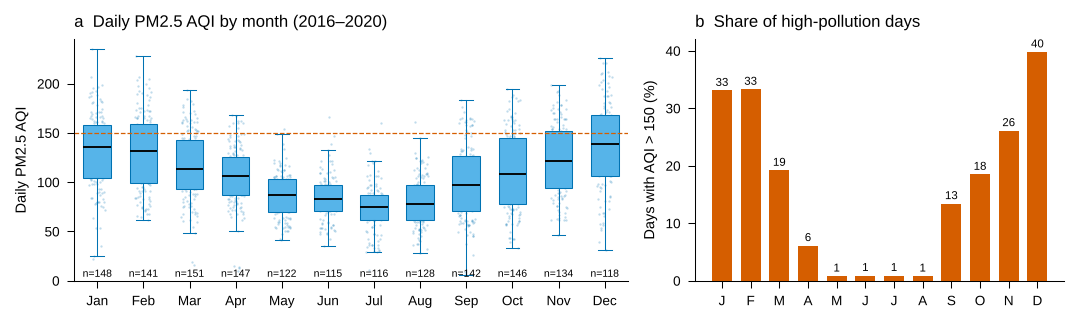

In [13]:
fig, (a, b) = plt.subplots(1, 2, figsize=(W2, 55 * MM), gridspec_kw={"width_ratios": [1.5, 1]})

bp = a.boxplot(by_m, widths=0.6, patch_artist=True, showfliers=False,
               medianprops=dict(color=OI["black"], lw=0.9),
               boxprops=dict(facecolor=OI["sky"], edgecolor=OI["blue"], lw=0.5),
               whiskerprops=dict(color=OI["blue"], lw=0.5), capprops=dict(color=OI["blue"], lw=0.5))
rng = np.random.default_rng(42)
for i, v in enumerate(by_m, start=1):
    a.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=1.2, color=OI["blue"], alpha=0.25, lw=0)
    a.text(i, 4, f"n={len(v)}", ha="center", fontsize=5)
a.axhline(150, color=OI["vermillion"], lw=0.6, ls="--")
a.set_xticks(range(1, 13), MONTHS)
a.set_ylim(0, 245)
a.set_ylabel("Daily PM2.5 AQI")
a.set_title("a  Daily PM2.5 AQI by month (2016–2020)", loc="left")

b.bar(range(1, 13), mtab["share_gt150_%"], color=OI["vermillion"], width=0.7)
for i, v in enumerate(mtab["share_gt150_%"], start=1):
    b.text(i, v + 0.8, f"{v:.0f}", ha="center", fontsize=5.5)
b.set_xticks(range(1, 13), [m[0] for m in MONTHS])
b.set_ylim(0, 42)
b.set_ylabel("Days with AQI > 150 (%)")
b.set_title("b  Share of high-pollution days", loc="left")
fig.tight_layout()
save(fig, "fig05_seasonal")
plt.show()

| Step | Evidence and response |
|---|---|
| Describe | Monthly median AQI peaks in December (138.5) and January (135.5) and bottoms out in July (74.5). The share of days above AQI 150 is 39.8% in December, 33% in January–February, and under 1% from May to August. |
| Notice | The season is **asymmetric**: pollution builds from September to December and declines more slowly from February to May. Within-month spread is wide in winter (IQR ≈ 55–62 AQI points) — high and moderate winter days both occur. |
| Limit | Month is a proxy. It bundles weather, crop-burning periods and heating/traffic patterns that this dataset cannot separate. |
| Check next | Month (or day-of-year) is a candidate model feature. Notebook 02 checks how much of the winter spread is explained by wind, rain and temperature. |

### 4.4 Day of week

In [14]:
DOW = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]
dtab = pd.DataFrame({
    "n": pm.groupby(pm.index.dayofweek).count(),
    "median": pm.groupby(pm.index.dayofweek).median(),
    "q1": pm.groupby(pm.index.dayofweek).quantile(.25),
    "q3": pm.groupby(pm.index.dayofweek).quantile(.75),
}).set_axis(DOW).round(1)

# remove the seasonal level: deviation from the 30-day rolling median
anom = (pm - roll).dropna()
dtab["median_deviation_from_30d"] = anom.groupby(anom.index.dayofweek).median().set_axis(DOW).round(1)
dtab

,n,median,q1,q3,median_deviation_from_30d
Mon,230,102.0,79.2,136.2,1.2
Tue,233,106.0,80.0,136.0,1.0
Wed,234,100.0,78.0,136.0,-0.5
Thu,231,103.0,76.0,132.5,-1.2
Fri,230,104.0,78.0,135.8,-0.5
Sat,228,103.5,77.0,139.0,0.0
Sun,222,102.5,76.0,131.8,0.2


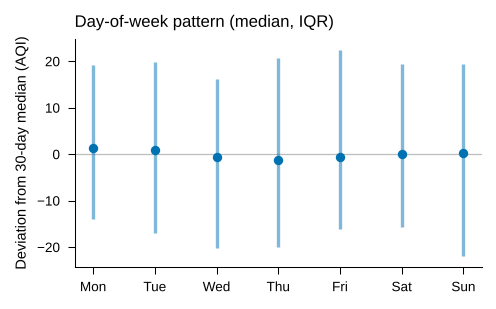

In [15]:
fig, ax = plt.subplots(figsize=(W1, 50 * MM))
g = [anom[anom.index.dayofweek == d] for d in range(7)]
med = [v.median() for v in g]
lo = [v.quantile(.25) for v in g]
hi = [v.quantile(.75) for v in g]
ax.axhline(0, color=GREY, lw=0.6)
ax.vlines(range(7), lo, hi, color=OI["blue"], lw=1.6, alpha=0.5)
ax.plot(range(7), med, "o", color=OI["blue"], ms=3.5)
ax.set_xticks(range(7), DOW)
ax.set_ylabel("Deviation from 30-day median (AQI)")
ax.set_title("Day-of-week pattern (median, IQR)", loc="left")
save(fig, "fig06_weekday")
plt.show()

| Step | Evidence and response |
|---|---|
| Describe | Weekday medians lie between AQI 100 and 106 (n = 222–234 per day). After removing the seasonal level, every weekday's median deviation is between −1.2 and +1.2 AQI points, and the IQRs overlap almost completely. |
| Notice | There is **no visible weekly cycle** at daily resolution, unlike the strong seasonal cycle. |
| Limit | Daily medians can hide within-day traffic peaks (rush hours); hourly data would be needed to test that. |
| Check next | **Drop day-of-week from RQ1's main claim** and report it as a null finding. Keep it as a weak candidate feature in RQ2 only if SHAP later shows it matters. |

### 4.5 Pollution episodes (AQI > 150)

In [16]:
high = (pm > 150)
high[pm.isna()] = False
rid = (high != high.shift()).cumsum()
ep = (pm[high].groupby(rid[high])
      .agg(start=lambda s: s.index.min().date(), days="size", peak="max")
      .reset_index(drop=True))
print(f"Episodes: {len(ep)} · single-day: {(ep.days == 1).sum()} · ≥3 days: {(ep.days >= 3).sum()} · "
      f"longest: {ep.days.max()} days")
print(f"Share of high days that belong to multi-day episodes: {ep.loc[ep.days > 1, 'days'].sum() / ep.days.sum():.1%}")
ep.sort_values("days", ascending=False).head(8)

Episodes: 101 · single-day: 38 · ≥3 days: 36 · longest: 10 days
Share of high days that belong to multi-day episodes: 85.7%


,start,days,peak
16,2016-10-04,10,188.0
67,2019-09-24,9,185.0
43,2018-01-13,8,196.0
76,2019-12-07,8,221.0
46,2018-02-04,7,188.0
40,2017-12-21,7,208.0
29,2017-01-22,6,192.0
72,2019-11-05,6,188.0


In [17]:
# persistence: how likely is a high day after a high day vs after a non-high day?
prev = pm.shift(1)
pair = pd.DataFrame({"today": pm > 150, "yesterday_high": prev > 150}).loc[pm.notna() & prev.notna()]
p_trans = pair.groupby("yesterday_high")["today"].agg(["mean", "size"]).rename(
    index={False: "yesterday ≤150", True: "yesterday >150"}, columns={"mean": "P(today >150)", "size": "n"})
p_trans["P(today >150)"] = p_trans["P(today >150)"].round(3)
p_trans

,P(today >150),n
yesterday_high,,
yesterday ≤150,0.07,1322
yesterday >150,0.64,258


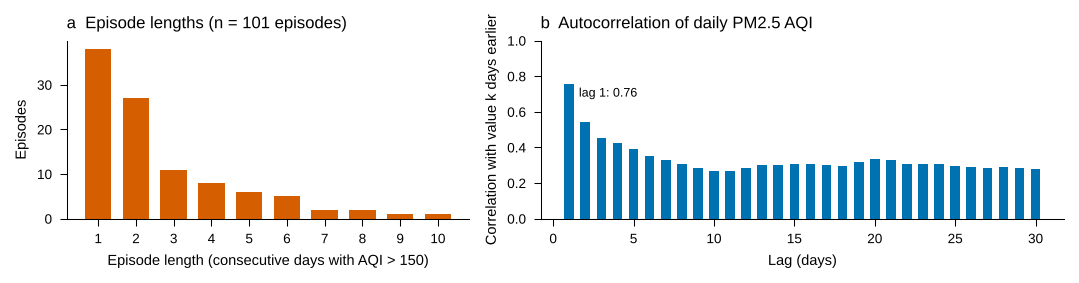

Lag-1: 0.757  Lag-7: 0.331  Lag-30: 0.28


In [18]:
lags = range(1, 31)
acf = [pm.corr(pm.shift(k)) for k in lags]
fig, (a, b) = plt.subplots(1, 2, figsize=(W2, 48 * MM), gridspec_kw={"width_ratios": [1, 1.3]})

cnt = ep["days"].value_counts().sort_index()
a.bar(cnt.index, cnt.values, color=OI["vermillion"], width=0.7)
a.set_xlabel("Episode length (consecutive days with AQI > 150)")
a.set_ylabel("Episodes")
a.set_xticks(cnt.index)
a.set_title(f"a  Episode lengths (n = {len(ep)} episodes)", loc="left")

b.bar(list(lags), acf, color=OI["blue"], width=0.6)
b.axhline(0, color=GREY, lw=0.5)
b.set_xlabel("Lag (days)")
b.set_ylabel("Correlation with value k days earlier")
b.set_ylim(0, 1)
b.text(1.6, acf[0] - 0.02, f"lag 1: {acf[0]:.2f}", fontsize=6, va="top")
b.set_title("b  Autocorrelation of daily PM2.5 AQI", loc="left")
fig.tight_layout()
save(fig, "fig07_persistence")
plt.show()
print("Lag-1:", round(acf[0], 3), " Lag-7:", round(acf[6], 3), " Lag-30:", round(acf[29], 3))

| Step | Evidence and response |
|---|---|
| Describe | The 266 high days form 101 episodes; 85.7% of high days belong to multi-day episodes (longest: 10 days, from 2016-10-04). After a high day, the next day is high 64% of the time (n = 258), versus 7% after a non-high day (n = 1,322). Lag-1 correlation is 0.76, falling to 0.33 at lag 7. |
| Notice | Pollution **persists** for a few days, then resets. The slow decay after lag 7 reflects the shared season rather than day-to-day memory. |
| Limit | Persistence is descriptive; it does not show what ends an episode (likely rain or a change of wind — notebook 02). |
| Check next | **Implication for RQ2:** a persistence forecast (tomorrow = today) will already be strong, so the gradient-boosted model must beat it, and a seasonal baseline, to be worth using. Lag-1 and lag-2 PM2.5 are the first features to include. |

### 4.6 Year-to-year comparison by month

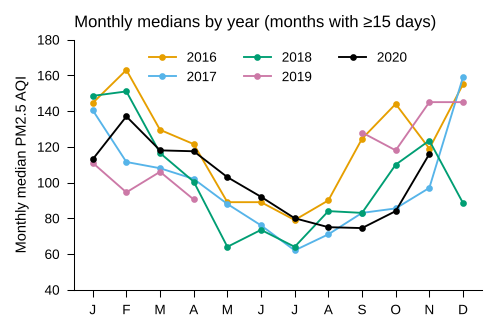

date,2016,2017,2018,2019,2020
date,,,,,
1,144.0,140.0,148.0,111.0,113.0
2,163.0,112.0,151.0,94.0,137.0
3,130.0,108.0,116.0,106.0,118.0
4,122.0,102.0,100.0,90.0,118.0
5,89.0,88.0,64.0,NaN,103.0
6,89.0,76.0,74.0,NaN,92.0
7,79.0,62.0,64.0,NaN,80.0
8,90.0,71.0,84.0,NaN,75.0
9,124.0,83.0,83.0,128.0,74.0


In [19]:
ym = pm.groupby([pm.index.year, pm.index.month]).agg(["median", "count"])
ym = ym[ym["count"] >= 15]["median"].unstack(0)   # require ≥15 observed days per month

YCOL = [OI["orange"], OI["sky"], OI["green"], OI["purple"], OI["black"]]
fig, ax = plt.subplots(figsize=(W1, 55 * MM))
for c, yr in zip(YCOL, ym.columns):
    ax.plot(ym.index, ym[yr], marker="o", ms=2.2, lw=0.9, color=c, label=str(yr))
ax.set_xticks(range(1, 13), [m[0] for m in MONTHS])
ax.set_ylabel("Monthly median PM2.5 AQI")
ax.legend(frameon=False, ncol=3, loc="upper center")
ax.set_ylim(40, 180)
ax.set_title("Monthly medians by year (months with ≥15 days)", loc="left")
save(fig, "fig08_years")
plt.show()
ym.round(0)

| Step | Evidence and response |
|---|---|
| Describe | All five years follow the same U-shaped curve. Months with fewer than 15 observed days are left out (May–August 2019 and December 2020, which has only 7 days in the file). |
| Notice | Differences between years in the same month can be large (December: 88 in 2018 vs 159 in 2017; February: 94 in 2019 vs 163 in 2016), so a single winter is a noisy sample. The raw annual medians (2016: 114, 2017: 92, 2018: 97, 2019: 114.5, 2020: 99) are misleading for 2019 because its clean summer months are missing. |
| Limit | Five winters are too few to claim a trend. 2020 includes COVID-19 restrictions, which could lower some months; this dataset cannot isolate that effect. |
| Check next | Do not make trend claims. Use a **chronological split** in RQ2 (e.g. train 2016–2019, test 2020) and report test-period conditions as a limitation. |

## 5. Export for modelling and Power BI

In [20]:
out = pm.to_frame()
out["observed"] = out["pm25_aqi"].notna()
out["year"] = out.index.year
out["month"] = out.index.month
out["day_of_week"] = out.index.dayofweek          # 0 = Monday
out["aqi_category"] = pd.cut(out["pm25_aqi"], BINS, labels=[l.replace("\n", " ") for l in LABELS]).astype("string")
out["high_pollution"] = (out["pm25_aqi"] > 150).astype("boolean")
out.loc[~out["observed"], "high_pollution"] = pd.NA   # blank, not False, on missing days
out.reset_index().to_csv(PROC / "pm25_daily.csv", index=False)
print("Saved:", (PROC / "pm25_daily.csv").relative_to(ROOT), out.shape)
out.head()

Saved: data/processed/pm25_daily.csv (1803, 7)


,pm25_aqi,observed,year,month,day_of_week,aqi_category,high_pollution
date,,,,,,,
2016-01-01,NaN,False,2016,1,4,<NA>,<NA>
2016-01-02,NaN,False,2016,1,5,<NA>,<NA>
2016-01-03,NaN,False,2016,1,6,<NA>,<NA>
2016-01-04,161.0,True,2016,1,0,Unhealthy,True
2016-01-05,170.0,True,2016,1,1,Unhealthy,True


## 6. Synthesis

| Evidence | What it means for the project |
|---|---|
| Values are US EPA AQI, not µg/m³ | All results are reported in AQI units; "high-pollution day" = AQI > 150 (≥ 55.5 µg/m³). |
| 1,608 / 1,803 days observed; one 119-day gap (May–Aug 2019) | No annual averages for 2019; lag features skip gaps instead of interpolating across them. |
| Strong seasonal cycle: Dec–Feb medians ≈ 132–139, Jul ≈ 75; 33–40% high days in Dec–Feb vs < 1% in May–Aug | Answers the seasonal half of RQ1. Month / day-of-year becomes a model feature. |
| No day-of-week effect | Reported as a null finding; weekday removed from RQ1's main claim. |
| High days cluster in multi-day episodes; lag-1 correlation ≈ 0.76 | Persistence is a strong baseline for RQ2; lag-1/lag-2 PM2.5 are core features. |

### Three next investigations
1. **Weather (notebook 02):** merge Open-Meteo daily wind speed, precipitation, temperature and humidity; test whether high days cluster under low wind, no rain and low temperature (the weather half of RQ1).
2. **Within-winter variation:** winter IQR is about 55–62 AQI points. Check whether weather explains which winter days become episodes.
3. **Modelling design (notebook 03):** chronological split with 2020 as test set; persistence and monthly-median baselines; features restricted to information available on the forecast day.

---
*AI assistance: code and draft commentary were produced with Claude (Anthropic) and checked against the printed tables. The author verified every number in the commentary.*

**Sources:** aqicn.org Air Quality Open Data Platform (AQI conversion of all pollutants); US EPA AQI breakpoints for PM2.5 (pre-2024 table).